
# ARTI 502 – Deep Learning
## Assignment 1: Training and Testing a Neural Network Using PyTorch

**Dataset:** MNIST  
**Framework:** PyTorch  
**Programming Language:** Python  

### Objective
The objective of this assignment is to build, train, test, and evaluate a neural network using the MNIST handwritten digit dataset. The assignment also explores how different hyperparameters and network architectures affect model performance.



### Group Information

**Group Number:** 6

| Student Name | Student ID |
|---|---|
| Fatimah Hassan Sowileh  | 2220006563 |
| Kawthar Hussain Althunayan | 2230001860 |
| Fadak mohammed alqassab | 2230006504 |
| Najaf AbdulKhaliq Alsabia | 2230004326 |
| Batool Ayman Aldauwagh | 2230003843 |
| Hawra Jafar Al-Yosuif  | 2230004521  |



---

## Task 1: Install and Import PyTorch

### Description
In this task, we import the PyTorch library and verify that it is installed and working correctly.


In [1]:

# Task 1: Import and verify PyTorch

import torch

# Display the installed PyTorch version
print("PyTorch version:", torch.__version__)

# Confirm successful import
print("PyTorch loaded successfully!")

PyTorch version: 2.11.0+cpu
PyTorch loaded successfully!



## Task 2: Download and Load the Dataset

### Description
In this task, we use PyTorch to download and load the MNIST dataset, which contains grayscale images of handwritten digits from 0 to 9. The dataset will be prepared for training and testing the neural network.


In [2]:

# Task 2: Download and Load the MNIST Dataset

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download the MNIST training dataset
full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Select 50,000 images for training
train_dataset = Subset(full_train_dataset, range(50000))

# Download the MNIST testing dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders with a batch size of 32
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Verify successful dataset loading
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("MNIST dataset loaded successfully!")

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 614kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.11MB/s]

Training samples: 50000
Testing samples: 10000
MNIST dataset loaded successfully!



## Task 3: Inspect the Dataset

### Description
In this task, we inspect the MNIST dataset by examining the size of the image tensors and visualizing sample handwritten digit images using Matplotlib.


In [3]:

# Task 3: Inspect the Dataset

# Get one batch of images and labels
images, labels = next(iter(train_loader))

# Display the tensor dimensions
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)


Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


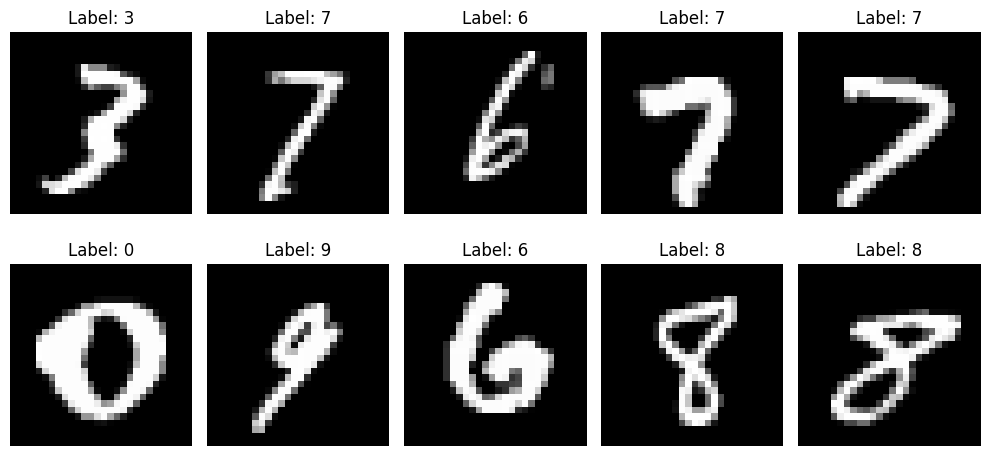

In [4]:

# Task 3: Visualize MNIST Images

import matplotlib.pyplot as plt

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:
# Task 4: Creating A Simple Network
import torch.nn as nn
import torch.nn.functional as F

class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super(SimpleNet, self).__init__()
        # First fully connected layer: connects input to hidden neurons
        self.fc1 = nn.Linear(input_size, hidden_size)
        # Second fully connected layer: connects hidden neurons to output classes
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Flatten the input tensor from (N, C, H, W) to (N, I) -> (32, 1, 28, 28) to (32, 784)
        x = torch.flatten(x, start_dim=1)


        # Hidden layer with ReLU activation
        x = F.relu(self.fc1(x))

        # Output layer
        x = self.fc2(x)
        return x

# Instantiate the model
model = SimpleNet()
print(model)

# --- Verification Step ---
# Pass one batch from Task 3 to verify tensor dimensions and forward pass
test_batch_images, test_batch_labels = next(iter(train_loader))
output = model(test_batch_images)


print("\n--- Verification ---")
print("Input batch shape :", test_batch_images.shape)
print("Output batch shape:", output.shape)
print("Expected output   : torch.Size([32, 10])")

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

--- Verification ---
Input batch shape : torch.Size([32, 1, 28, 28])
Output batch shape: torch.Size([32, 10])
Expected output   : torch.Size([32, 10])


### Task 5: Training Function

**Description**

we define a training function to train the neural network using the MNIST dataset. CrossEntropyLoss used as the loss function and SGD as the optimizer.
The function performs forward propagation, calculates the loss, updates the model parameters using backpropagation, and displays the training loss and accuracy for each epoch.

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim

def train(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):
    # Define the loss function
    criterion = nn.CrossEntropyLoss()

    # Define the optimizer
    optimizer = optim.SGD(
        net.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    # Train the network
    net.train()

    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            # Flatten images from (batch_size, 1, 28, 28) to (batch_size, 784)
            images = images.view(images.size(0), -1)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = net(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backward pass
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Track loss and accuracy
            running_loss += loss.item()
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / len(train_loader)
        accuracy = 100 * correct / total

        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {epoch_loss:.4f}, "
            f"Accuracy: {accuracy:.2f}%"
        )

    print("Training completed!")


In [7]:

# Train the Neural Network

model = SimpleNet()

train(
    net=model,
    train_loader=train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9
)


Epoch [1/5], Loss: 0.3859, Accuracy: 89.04%
Epoch [2/5], Loss: 0.1774, Accuracy: 94.92%
Epoch [3/5], Loss: 0.1258, Accuracy: 96.36%
Epoch [4/5], Loss: 0.0976, Accuracy: 97.10%
Epoch [5/5], Loss: 0.0797, Accuracy: 97.71%
Training completed!


### Task 6: Training Network

**Description**

In this task, we instantiate a new `SimpleNet` and train it on the 50,000 MNIST training images. The training function extends the one from Task 5: during training it prints debug information (epoch, batch number, current loss and running accuracy) every 200 mini-batches, and at the end of every epoch it prints the epoch summary.

The function also **returns a list of the loss of every mini-batch**, plus the loss and accuracy of each epoch, so we can plot the whole training process once it has finished.

**Hyperparameters used:** epochs = 5, batch size = 32, learning rate = 0.01, momentum = 0.9, loss = CrossEntropyLoss, optimizer = SGD.


In [8]:
# Task 6: Training function with debug output that returns the losses

import torch
import torch.nn as nn
import torch.optim as optim

def train_with_debug(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9, print_every=200):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

    batch_losses = []      # loss of every mini-batch
    epoch_losses = []      # average loss of each epoch
    epoch_accuracies = []  # accuracy of each epoch

    net.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader, start=1):
            optimizer.zero_grad()              # clear old gradients
            outputs = net(images)              # forward pass (model flattens to 32 x 784)
            loss = criterion(outputs, labels)  # compute loss
            loss.backward()                    # backpropagation
            optimizer.step()                   # update weights

            # Track loss and accuracy
            batch_losses.append(loss.item())
            running_loss += loss.item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

            # Debug information
            if batch_idx % print_every == 0 or batch_idx == len(train_loader):
                print(f"Epoch [{epoch + 1}/{epochs}] | "
                      f"Batch [{batch_idx}/{len(train_loader)}] | "
                      f"Current Loss: {loss.item():.4f} | "
                      f"Accuracy so far: {100 * correct / total:.2f}%")

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = 100 * correct / total
        epoch_losses.append(epoch_loss)
        epoch_accuracies.append(epoch_acc)
        print(f"==> End of Epoch {epoch + 1}: Avg Loss = {epoch_loss:.4f}, Accuracy = {epoch_acc:.2f}%\n")

    print("Training completed!")
    return batch_losses, epoch_losses, epoch_accuracies


In [9]:
# Task 6: Instantiate a NEW network and train it

torch.manual_seed(42)        # for reproducible results
net = SimpleNet()            # new, untrained network from Task 4
print(net)

batch_losses, epoch_losses, epoch_accuracies = train_with_debug(
    net=net,
    train_loader=train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9,
    print_every=200
)

print("Number of mini-batch losses recorded:", len(batch_losses))


SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Epoch [1/5] | Batch [200/1563] | Current Loss: 0.4467 | Accuracy so far: 73.80%
Epoch [1/5] | Batch [400/1563] | Current Loss: 0.1872 | Accuracy so far: 81.08%
Epoch [1/5] | Batch [600/1563] | Current Loss: 0.5661 | Accuracy so far: 84.28%
Epoch [1/5] | Batch [800/1563] | Current Loss: 0.3554 | Accuracy so far: 86.00%
Epoch [1/5] | Batch [1000/1563] | Current Loss: 0.1962 | Accuracy so far: 87.00%
Epoch [1/5] | Batch [1200/1563] | Current Loss: 0.1658 | Accuracy so far: 87.85%
Epoch [1/5] | Batch [1400/1563] | Current Loss: 0.1651 | Accuracy so far: 88.55%
Epoch [1/5] | Batch [1563/1563] | Current Loss: 0.0319 | Accuracy so far: 88.95%
==> End of Epoch 1: Avg Loss = 0.3911, Accuracy = 88.95%

Epoch [2/5] | Batch [200/1563] | Current Loss: 0.3768 | Accuracy so far: 94.52%
Epoch [2/5] | Batch [400/1563] | Current Loss: 0.0978 | Accuracy so far: 94.36%
Ep

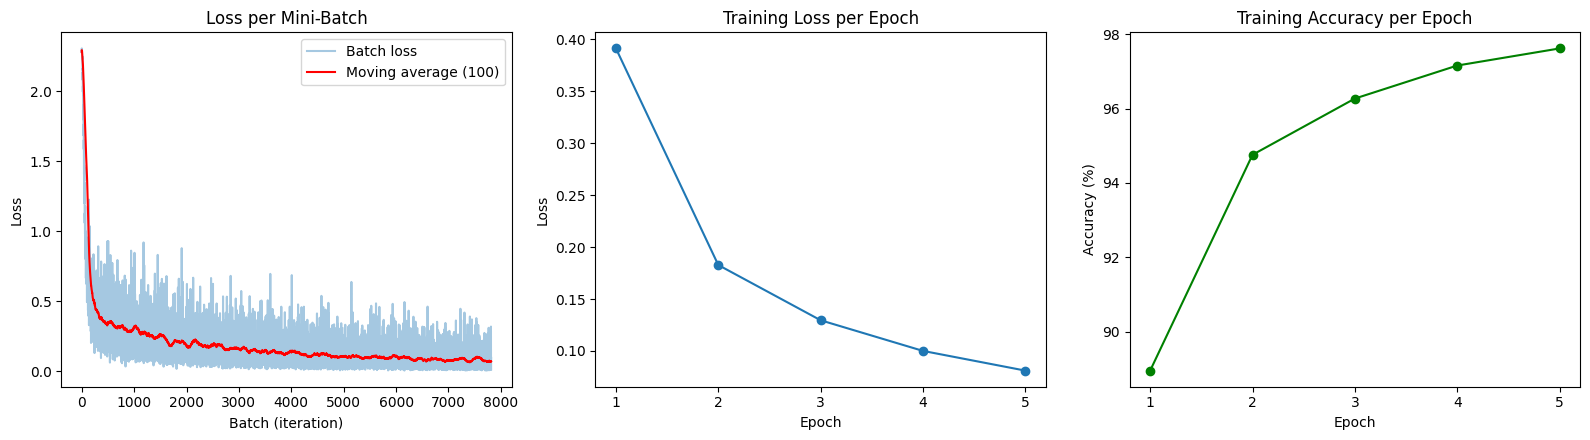

In [10]:
# Task 6: Graphs of the overall training process

import matplotlib.pyplot as plt

epochs_range = range(1, len(epoch_losses) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Loss of every mini-batch
axes[0].plot(batch_losses, alpha=0.4, label="Batch loss")
window = 100
smoothed = [sum(batch_losses[max(0, i - window):i + 1]) / len(batch_losses[max(0, i - window):i + 1])
            for i in range(len(batch_losses))]
axes[0].plot(smoothed, color="red", label=f"Moving average ({window})")
axes[0].set_title("Loss per Mini-Batch")
axes[0].set_xlabel("Batch (iteration)")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2) Average loss per epoch
axes[1].plot(epochs_range, epoch_losses, marker="o")
axes[1].set_title("Training Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(list(epochs_range))

# 3) Accuracy per epoch
axes[2].plot(epochs_range, epoch_accuracies, marker="o", color="green")
axes[2].set_title("Training Accuracy per Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()


## Task 7: Testing the Network

### Description
In this task, we test the network trained in Task 6 on the 10,000 MNIST test images, which the model never saw during training. First we compute the overall test loss and accuracy. Then we display a few test images with the true label and the network's prediction, so we can see where the model is correct and where it makes mistakes.

In [11]:
# Task 7: Testing function

import torch
import torch.nn as nn

def test(net, test_loader):
    criterion = nn.CrossEntropyLoss()
    net.eval()                      # switch to evaluation mode

    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():           # no gradients needed for testing
        for images, labels in test_loader:
            outputs = net(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item()
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = test_loss / len(test_loader)
    accuracy = 100 * correct / total

    print(f"Test samples : {total}")
    print(f"Correct      : {correct}")
    print(f"Test Loss    : {avg_loss:.4f}")
    print(f"Test Accuracy: {accuracy:.2f}%")
    return avg_loss, accuracy

test_loss, test_accuracy = test(net, test_loader)

Test samples : 10000
Correct      : 9744
Test Loss    : 0.0881
Test Accuracy: 97.44%


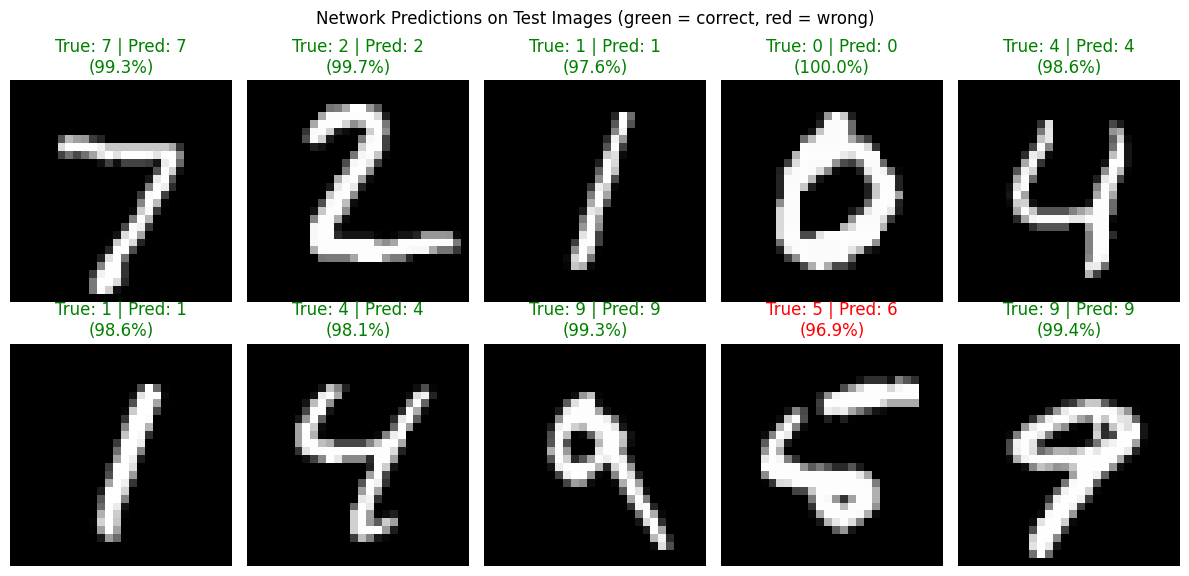

Correct predictions in this batch: 31/32


In [12]:
# Task 7: Test the network on a few test images

import matplotlib.pyplot as plt

net.eval()
test_images, test_labels = next(iter(test_loader))   # one batch of 32 test images

with torch.no_grad():
    outputs = net(test_images)
    probabilities = torch.softmax(outputs, dim=1)
    predictions = outputs.argmax(dim=1)

# Show the first 10 images with true label vs predicted label
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    true_label = test_labels[i].item()
    pred_label = predictions[i].item()
    confidence = probabilities[i, pred_label].item() * 100

    ax.imshow(test_images[i].squeeze(), cmap="gray")
    color = "green" if pred_label == true_label else "red"
    ax.set_title(f"True: {true_label} | Pred: {pred_label}\n({confidence:.1f}%)", color=color)
    ax.axis("off")

plt.suptitle("Network Predictions on Test Images (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

# Text summary for the same batch
batch_correct = (predictions == test_labels).sum().item()
print(f"Correct predictions in this batch: {batch_correct}/{len(test_labels)}")

## Task 8: Tuning the Parameters and Model Architecture

### Description
In this task, we tune the network in two steps:

1. **Hyperparameter tuning:** we keep the same `SimpleNet` architecture from Task 4 (784 → 128 → 10) and train it with different combinations of **learning rate** and **momentum**.
2. **Architecture tuning:** using the best learning rate and momentum from step 1, we train networks with a different **number of hidden layers** and **number of neurons** per layer.

For a fair comparison, every run uses the same settings: 5 epochs, batch size 32, CrossEntropyLoss, SGD, and the same random seed (`torch.manual_seed(42)`) before creating each network. Each model is evaluated on the 10,000 test images, and the best result is the one with the **highest test accuracy** (test loss is used to break ties).

In [13]:
# Task 8: Helper functions for tuning (quiet training + evaluation)

import torch
import torch.nn as nn
import torch.optim as optim

def train_quiet(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):
    # Same training loop as Task 5/6, without the per-batch printing
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

    net.train()
    for epoch in range(epochs):
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            optimizer.zero_grad()
            outputs = net(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    # Loss and accuracy of the last epoch
    return running_loss / len(train_loader), 100 * correct / total


def evaluate(net, test_loader):
    # Same as the Task 7 test function, without printing
    criterion = nn.CrossEntropyLoss()
    net.eval()
    test_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = net(images)
            test_loss += criterion(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return test_loss / len(test_loader), 100 * correct / total

### Part 1: Tuning Learning Rate and Momentum

We test 3 learning rates (0.001, 0.01, 0.1) × 3 momentum values (0.0, 0.5, 0.9) = **9 runs** on the Task 4 `SimpleNet` (one hidden layer, 128 neurons).

In [14]:
# Task 8 - Part 1: Grid search over learning rate and momentum

import pandas as pd

learning_rates = [0.001, 0.01, 0.1]
momentums = [0.0, 0.5, 0.9]
EPOCHS = 5

lr_results = []
for lr in learning_rates:
    for m in momentums:
        torch.manual_seed(42)
        net_lr = SimpleNet()                       # same architecture as Task 4
        train_loss, train_acc = train_quiet(net_lr, train_loader,
                                            epochs=EPOCHS, learning_rate=lr, momentum=m)
        test_loss_lr, test_acc_lr = evaluate(net_lr, test_loader)

        lr_results.append({
            "Learning Rate": lr, "Momentum": m,
            "Train Loss": round(train_loss, 4), "Train Acc (%)": round(train_acc, 2),
            "Test Loss": round(test_loss_lr, 4), "Test Acc (%)": round(test_acc_lr, 2)
        })
        print(f"lr={lr:<6} momentum={m:<4} | Train Loss={train_loss:.4f} | "
              f"Test Loss={test_loss_lr:.4f} | Test Acc={test_acc_lr:.2f}%")

lr_df = pd.DataFrame(lr_results).sort_values(["Test Acc (%)", "Test Loss"],
                                             ascending=[False, True]).reset_index(drop=True)
print("\nResults sorted from best to worst:")
display(lr_df)

best_lr = lr_df.loc[0, "Learning Rate"]
best_momentum = lr_df.loc[0, "Momentum"]
print(f"\nBest parameters: learning rate = {best_lr}, momentum = {best_momentum} "
      f"-> Test Loss = {lr_df.loc[0, 'Test Loss']}, Test Accuracy = {lr_df.loc[0, 'Test Acc (%)']}%")

lr=0.001  momentum=0.0  | Train Loss=0.7506 | Test Loss=0.6625 | Test Acc=85.52%
lr=0.001  momentum=0.5  | Train Loss=0.4910 | Test Loss=0.4382 | Test Acc=88.83%
lr=0.001  momentum=0.9  | Train Loss=0.2887 | Test Loss=0.2678 | Test Acc=92.42%
lr=0.01   momentum=0.0  | Train Loss=0.2886 | Test Loss=0.2664 | Test Acc=92.50%
lr=0.01   momentum=0.5  | Train Loss=0.2202 | Test Loss=0.2051 | Test Acc=94.17%
lr=0.01   momentum=0.9  | Train Loss=0.0811 | Test Loss=0.0881 | Test Acc=97.44%
lr=0.1    momentum=0.0  | Train Loss=0.0807 | Test Loss=0.0876 | Test Acc=97.32%
lr=0.1    momentum=0.5  | Train Loss=0.0546 | Test Loss=0.0726 | Test Acc=97.76%
lr=0.1    momentum=0.9  | Train Loss=0.1024 | Test Loss=0.1675 | Test Acc=96.02%

Results sorted from best to worst:


,Learning Rate,Momentum,Train Loss,Train Acc (%),Test Loss,Test Acc (%)
0,0.100,0.5,0.0546,98.35,0.0726,97.76
1,0.010,0.9,0.0811,97.62,0.0881,97.44
2,0.100,0.0,0.0807,97.66,0.0876,97.32
3,0.100,0.9,0.1024,97.19,0.1675,96.02
4,0.010,0.5,0.2202,93.83,0.2051,94.17
5,0.010,0.0,0.2886,91.79,0.2664,92.50
6,0.001,0.9,0.2887,91.80,0.2678,92.42
7,0.001,0.5,0.4910,87.46,0.4382,88.83
8,0.001,0.0,0.7506,83.49,0.6625,85.52



Best parameters: learning rate = 0.1, momentum = 0.5 -> Test Loss = 0.0726, Test Accuracy = 97.76%


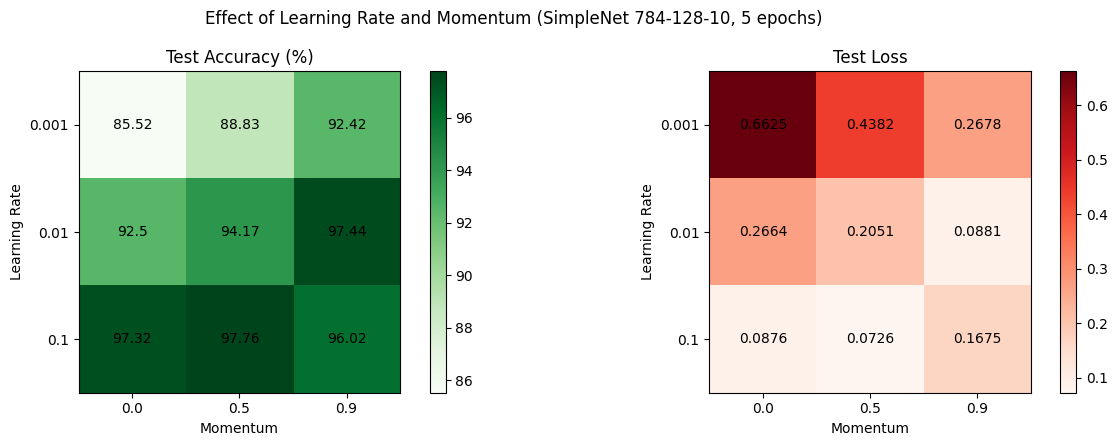

In [15]:
# Task 8 - Part 1: Visualize the learning rate / momentum results

import matplotlib.pyplot as plt

acc_table = lr_df.pivot(index="Learning Rate", columns="Momentum", values="Test Acc (%)")
loss_table = lr_df.pivot(index="Learning Rate", columns="Momentum", values="Test Loss")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, table, title, cmap in [(axes[0], acc_table, "Test Accuracy (%)", "Greens"),
                               (axes[1], loss_table, "Test Loss", "Reds")]:
    im = ax.imshow(table.values, cmap=cmap)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    ax.set_xlabel("Momentum")
    ax.set_ylabel("Learning Rate")
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.4g}", ha="center", va="center")
    fig.colorbar(im, ax=ax)

plt.suptitle("Effect of Learning Rate and Momentum (SimpleNet 784-128-10, 5 epochs)")
plt.tight_layout()
plt.show()

### Part 2: Tuning the Model Architecture

We build a flexible network where the number of hidden layers and the number of neurons in each layer are passed as a list. For example, `[256, 128]` means two hidden layers with 256 and 128 neurons. Every hidden layer uses ReLU, and the input is flattened from (N × 1 × 28 × 28) to (N × 784) exactly like in Task 4.

All architectures are trained with the **best learning rate and momentum from Part 1**.

In [16]:
# Task 8 - Part 2: Flexible network with any number of hidden layers / neurons

class FlexibleNet(nn.Module):
    def __init__(self, hidden_sizes, input_size=784, num_classes=10):
        super(FlexibleNet, self).__init__()
        layers = []
        in_features = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(in_features, h))   # fully connected layer
            layers.append(nn.ReLU())                   # non-linearity
            in_features = h
        layers.append(nn.Linear(in_features, num_classes))  # output layer
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)   # (N, 1, 28, 28) -> (N, 784)
        return self.layers(x)

# Quick check
print(FlexibleNet([256, 128]))

FlexibleNet(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [17]:
# Task 8 - Part 2: Train and compare different architectures

architectures = [
    [64],             # 1 hidden layer
    [128],            # 1 hidden layer (same as Task 4)
    [256],            # 1 hidden layer
    [512],            # 1 hidden layer
    [128, 64],        # 2 hidden layers
    [256, 128],       # 2 hidden layers
    [512, 256],       # 2 hidden layers
    [256, 128, 64],   # 3 hidden layers
    [512, 256, 128],  # 3 hidden layers
]

arch_results = []
for hidden in architectures:
    torch.manual_seed(42)
    net_arch = FlexibleNet(hidden)
    n_params = sum(p.numel() for p in net_arch.parameters())
    train_loss, train_acc = train_quiet(net_arch, train_loader, epochs=EPOCHS,
                                        learning_rate=best_lr, momentum=best_momentum)
    test_loss_a, test_acc_a = evaluate(net_arch, test_loader)

    name = "784-" + "-".join(map(str, hidden)) + "-10"
    arch_results.append({
        "Architecture": name, "Hidden Layers": len(hidden), "Parameters": n_params,
        "Train Loss": round(train_loss, 4), "Train Acc (%)": round(train_acc, 2),
        "Test Loss": round(test_loss_a, 4), "Test Acc (%)": round(test_acc_a, 2)
    })
    print(f"{name:<20} | layers={len(hidden)} | params={n_params:>7} | "
          f"Test Loss={test_loss_a:.4f} | Test Acc={test_acc_a:.2f}%")

arch_df = pd.DataFrame(arch_results).sort_values(["Test Acc (%)", "Test Loss"],
                                                 ascending=[False, True]).reset_index(drop=True)
print("\nResults sorted from best to worst:")
display(arch_df)

best_arch_name = arch_df.loc[0, "Architecture"]
best_hidden = [int(h) for h in best_arch_name.split("-")[1:-1]]
print(f"\nBest architecture: {best_arch_name} -> Test Loss = {arch_df.loc[0, 'Test Loss']}, "
      f"Test Accuracy = {arch_df.loc[0, 'Test Acc (%)']}%")

784-64-10            | layers=1 | params=  50890 | Test Loss=0.0922 | Test Acc=97.18%
784-128-10           | layers=1 | params= 101770 | Test Loss=0.0726 | Test Acc=97.76%
784-256-10           | layers=1 | params= 203530 | Test Loss=0.0685 | Test Acc=97.79%
784-512-10           | layers=1 | params= 407050 | Test Loss=0.0658 | Test Acc=97.88%
784-128-64-10        | layers=2 | params= 109386 | Test Loss=0.0894 | Test Acc=97.30%
784-256-128-10       | layers=2 | params= 235146 | Test Loss=0.0767 | Test Acc=97.71%
784-512-256-10       | layers=2 | params= 535818 | Test Loss=0.0713 | Test Acc=97.83%
784-256-128-64-10    | layers=3 | params= 242762 | Test Loss=0.0896 | Test Acc=97.46%
784-512-256-128-10   | layers=3 | params= 567434 | Test Loss=0.0717 | Test Acc=97.97%

Results sorted from best to worst:


,Architecture,Hidden Layers,Parameters,Train Loss,Train Acc (%),Test Loss,Test Acc (%)
0,784-512-256-128-10,3,567434,0.0406,98.73,0.0717,97.97
1,784-512-10,1,407050,0.0419,98.78,0.0658,97.88
2,784-512-256-10,2,535818,0.0348,98.87,0.0713,97.83
3,784-256-10,1,203530,0.0470,98.61,0.0685,97.79
4,784-128-10,1,101770,0.0546,98.35,0.0726,97.76
5,784-256-128-10,2,235146,0.0411,98.66,0.0767,97.71
6,784-256-128-64-10,3,242762,0.0486,98.48,0.0896,97.46
7,784-128-64-10,2,109386,0.0505,98.41,0.0894,97.30
8,784-64-10,1,50890,0.0692,97.81,0.0922,97.18



Best architecture: 784-512-256-128-10 -> Test Loss = 0.0717, Test Accuracy = 97.97%


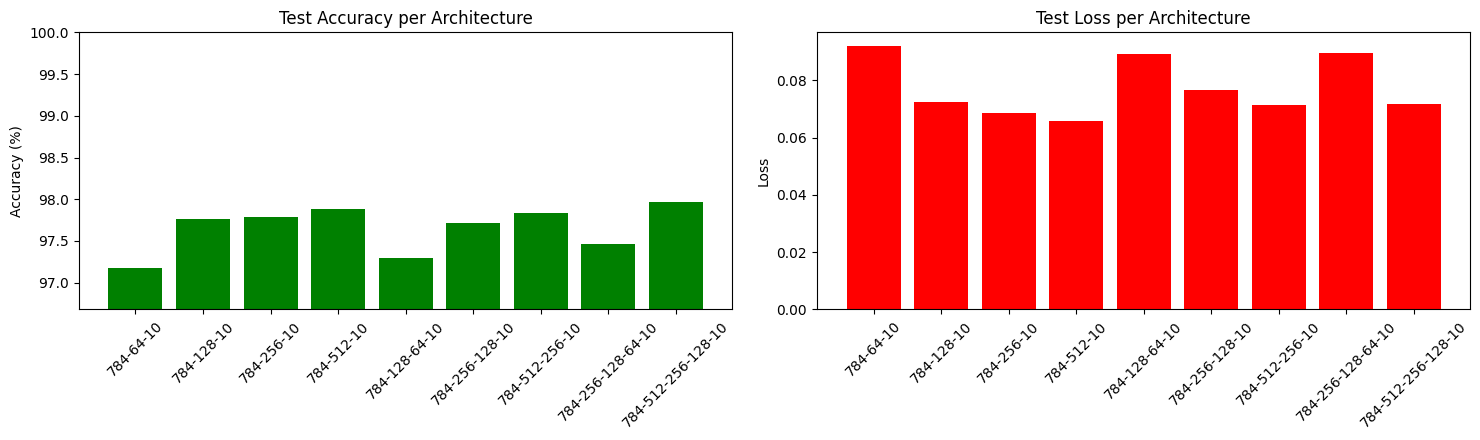

In [18]:
# Task 8 - Part 2: Visualize the architecture results

plot_df = pd.DataFrame(arch_results)   # keep the original order for plotting

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(plot_df["Architecture"], plot_df["Test Acc (%)"], color="green")
axes[0].set_title("Test Accuracy per Architecture")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(plot_df["Test Acc (%)"].min() - 0.5, 100)

axes[1].bar(plot_df["Architecture"], plot_df["Test Loss"], color="red")
axes[1].set_title("Test Loss per Architecture")
axes[1].set_ylabel("Loss")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Final Model: Best Parameters + Best Architecture

We train the final model one more time with the best learning rate, momentum and architecture, using the Task 6 training function so we get the full debug output and training graphs, then test it with the Task 7 test function.

In [19]:
# Task 8: Train the final best model

torch.manual_seed(42)
best_net = FlexibleNet(best_hidden)
print(best_net)
print(f"Learning rate = {best_lr}, Momentum = {best_momentum}, Epochs = {EPOCHS}\n")

best_batch_losses, best_epoch_losses, best_epoch_accs = train_with_debug(
    net=best_net,
    train_loader=train_loader,
    epochs=EPOCHS,
    learning_rate=best_lr,
    momentum=best_momentum,
    print_every=400
)

print("\n--- Final test results ---")
best_test_loss, best_test_acc = test(best_net, test_loader)

print("\n--- Comparison with the baseline (Task 6/7) ---")
print(f"Baseline : 784-128-10, lr=0.01, momentum=0.9 -> Test Loss = {test_loss:.4f}, Test Acc = {test_accuracy:.2f}%")
print(f"Best     : {best_arch_name}, lr={best_lr}, momentum={best_momentum} "
      f"-> Test Loss = {best_test_loss:.4f}, Test Acc = {best_test_acc:.2f}%")

FlexibleNet(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)
Learning rate = 0.1, Momentum = 0.5, Epochs = 5

Epoch [1/5] | Batch [400/1563] | Current Loss: 0.3289 | Accuracy so far: 75.46%
Epoch [1/5] | Batch [800/1563] | Current Loss: 0.2760 | Accuracy so far: 83.98%
Epoch [1/5] | Batch [1200/1563] | Current Loss: 0.0863 | Accuracy so far: 87.39%
Epoch [1/5] | Batch [1563/1563] | Current Loss: 0.0951 | Accuracy so far: 89.14%
==> End of Epoch 1: Avg Loss = 0.3411, Accuracy = 89.14%

Epoch [2/5] | Batch [400/1563] | Current Loss: 0.4264 | Accuracy so far: 96.33%
Epoch [2/5] | Batch [800/1563] | Current Loss: 0.1621 | Accuracy so far: 96.44%
Epoch [2/5] | Batch [1200/1563] | Current Loss: 0.1513 | Accuracy so far:

### Results Discussion

#### Best results

| | Setting | Test Loss | Test Accuracy |
|---|---|---|---|
| Baseline (Task 6/7) | 784-128-10, lr = 0.01, momentum = 0.9 | 0.0881 | 97.44% |
| Best parameters (Part 1) | 784-128-10, **lr = 0.1, momentum = 0.5** | 0.0726 | 97.76% |
| Best architecture (Part 2) | **784-512-256-128-10**, lr = 0.1, momentum = 0.5 | 0.0717 | **97.97%** |

The final model correctly classified **9,797 / 10,000** test images. Compared to the baseline, test accuracy improved by **0.53%** and test loss dropped from 0.0881 to 0.0717.

#### Part 1: Learning rate and momentum
- **Learning rate:** with lr = 0.001 the model learned too slowly in 5 epochs. Without momentum it only reached 85.52% (test loss 0.6625). Increasing the learning rate to 0.01 and 0.1 improved the results in almost every case.
- **Momentum:** at lr = 0.001 and lr = 0.01, increasing momentum from 0 → 0.5 → 0.9 always improved accuracy (for example 92.50% → 94.17% → 97.44% at lr = 0.01).
- **Too large a step:** lr = 0.1 with momentum = 0.9 was worse than lr = 0.1 with momentum = 0.5 (96.02% vs 97.76%), and its test loss was more than double (0.1675 vs 0.0726). The combined step was too large, so the updates overshot the minimum.
- **Effective step size:** with momentum, the effective step is roughly lr / (1 − momentum). The two settings with the same effective step of 0.1 (lr = 0.01, m = 0.9 and lr = 0.1, m = 0.0) gave almost the same results (97.44% / 0.0881 and 97.32% / 0.0876). The best setting (lr = 0.1, m = 0.5) has an effective step of 0.2. The worst high-lr setting (lr = 0.1, m = 0.9) has an effective step of 1.0.

#### Part 2: Number of layers and neurons
- **Number of neurons:** with one hidden layer, accuracy increased and test loss decreased every time the width increased. 64 → 128 → 256 → 512 neurons gave 97.18% → 97.76% → 97.79% → 97.88%. The gain gets smaller after 128 neurons while the number of parameters doubles each time.
- **Number of layers:** adding layers did not always help. 784-128-64-10 (97.30%) and 784-256-128-64-10 (97.46%) were worse than a single hidden layer of 128 or 256 neurons. Depth helped only when the layers were wide: 784-512-256-128-10 gave the highest accuracy (97.97%).
- **Lowest loss vs highest accuracy:** the lowest test loss came from the single-layer 784-512-10 (0.0658, 97.88%), not from the most accurate model (0.0717, 97.97%). The two models differ by only 0.09% in accuracy, while 784-512-10 has fewer parameters (407,050 vs 567,434).
- **Overfitting check:** the final model reached 98.73% training accuracy and 97.97% test accuracy, a gap of 0.76%. This small gap shows that the model generalizes well to unseen images.

#### Conclusion
The learning rate and momentum had a much larger effect on performance (85.52% to 97.76%) than the architecture (97.18% to 97.97%). On MNIST, a simple network with a well-chosen learning rate and momentum already performs very well, and making it wider or deeper adds less than 1% accuracy.
